# Control Fundamentals: Feedback, Error and Stability

`01_control_fundamentals` | level 0 | experiment id(s): `exp_01_feedback_fundamentals`

| Dimension | Status |
|---|---|
| Content | All 15 sections written. |
| Software | Executed from a clean kernel; library covered by unit tests. |
| Research | 3 reference(s), verification status shown in section 4. Recent literature (2020 onward) was not searched. |
| Simulation | Executed. Results below were generated by this notebook. |
| Hardware | Not validated on hardware. No physical experiment was performed. |

All parameter values are illustrative and are not taken from a measured machine or plant unless a dataset section says so.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import control_lab
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True})
print('control_lab', control_lab.__version__)

control_lab 0.1.0


## 1. Learning Objectives

After this notebook you can:
- Explain what feedback buys (disturbance and uncertainty reduction) and what it costs
  (loop delay limits the usable gain).
- Derive the closed-loop transfer function and steady-state error of a P-controlled first-order
  plant, and verify the result against a simulation to within 1e-3.
- Predict from the ultimate gain `Ku` whether a loop with dead time is stable, and confirm it in
  simulation.

## 2. Real-World Engineering Problem

A heated tank, a conveyor drive and a pump all share one problem: the output (temperature,
speed, flow) drifts away from the target when the load or the plant changes. An open-loop
setting that was correct in the morning is wrong after the load changes. Feedback measures the
output and corrects the input. The price is that measurement and actuator delay turn a high
gain into an oscillation. This notebook quantifies both effects on one plant with `K = 2`,
`T = 10 s`.

## 3. Research Background

Feedback regulators were used on steam engines and in process plants long before a general
theory existed; the frequency-domain stability tools (Nyquist, Bode) and the later state-space
view are the base of modern design. The textbook treatment used here follows Astrom and Murray
(2021) and the PID-oriented view of Astrom and Hagglund (1995). Section 4 lists what was
verified.

## 4. Research Literature

Selected sources (details and verification status in the table below). They are textbooks, so
they give theory and method, not the numerical results shown here. Recent research literature
was not searched for this notebook.

### Reference table

| Key | Citation | Role | Limitation | Verification |
|---|---|---|---|---|
| am2021 | Astrom, K. J.; Murray, R. M. (2021). Feedback Systems: An Introduction for Scientists and Engineers, 2nd ed.. Princeton University Press. ISBN 978-0-691-19398-4. | Modern introduction to feedback, modeling, stability, PID and robustness. | Broad textbook; industrial specifics are limited. | verified (2026-11-25, web search of publisher/index/library record). Library record gives publisher, year and ISBN. |
| ah1995 | Astrom, K. J.; Hagglund, T. (1995). PID Controllers: Theory, Design, and Tuning, 2nd ed.. ISA (Instrument Society of America). ISBN 1-55617-516-7. | Standard reference on PID structure, anti-windup, filtering and tuning. | Pre-dates much current autotuning practice. | verified (2026-11-25, web search of publisher/index/library record). University repository record gives publisher, year, ISBN, 343 pages. |
| seborg2016 | Seborg, D. E.; Edgar, T. F.; Mellichamp, D. A.; Doyle, F. J. (2016). Process Dynamics and Control, 4th ed.. Wiley. ISBN 978-1-119-28591-5. | Process-control textbook: FOPDT models, reaction-curve methods, tuning rules. | Which tuning rules and identification methods it covers was not checked page by page in this build. | verified (2026-11-25, web search of publisher/index/library record). Publisher listing gives edition, year and ISBN. |

Verification here means the bibliographic record was found on a publisher, index, library or author page. It does not mean the full text was read, and no numerical claim in this notebook is taken from these papers.

## 5. Mathematical Foundation

Plant: $G(s)=\dfrac{K e^{-Ls}}{Ts+1}$ with $K$ in output units per input unit, $T$ the time
constant in seconds and $L$ the dead time in seconds. Controller: proportional gain $K_c$.

**Closed loop (L = 0).** With $C=K_c$ and unity feedback,
$$\frac{Y}{R}=\frac{K_cK}{Ts+1+K_cK}=\frac{K_cK/(1+K_cK)}{\tau_{cl}s+1},\qquad
\tau_{cl}=\frac{T}{1+K_cK}.$$
For a unit step, the steady-state error is $e_{ss}=\dfrac{1}{1+K_cK}$ (the loop gain $K_cK$ is
the only thing that sets it).

**Disturbance.** A constant input disturbance $d$ gives $y_{ss}=Kd$ open loop and
$y_{ss}=\dfrac{Kd}{1+K_cK}$ closed loop.

**Sensitivity.** $S=\dfrac{1}{1+KC}$ is the fractional change of the closed-loop output per
fractional change of the plant gain at zero frequency.

**Stability with delay.** At the phase crossover frequency $\omega_u$,
$-\omega_uL-\arctan(\omega_uT)=-\pi$. The ultimate gain is
$K_u=\dfrac{\sqrt{1+(\omega_uT)^2}}{K}$. The P loop is stable for $K_c<K_u$.

## 6. System Modeling

`FOPDTPlant` discretises the first-order part exactly for a zero-order-hold input and realises
the delay as a whole number of samples. Sampling time `Ts = 0.1 s`, so every delay used below is
an exact multiple of the sampling time. Input disturbances are added before the delay.

## 7. Dataset and Measurement Data

No dataset. This notebook uses a simulated plant with illustrative parameters
(`K = 2`, `T = 10 s`, `L` varied). Nothing here is a measurement.

## 8. Algorithm Architecture

Signal flow: `r -> (+) -> e -> Kc -> u -> [+ d] -> plant -> y`, with `y` fed back to the summing
junction. The sampled loop order is: measure, compute `u`, advance the plant one sample.

## 9. Algorithm Implementation

In [2]:
from control_lab.controllers import PID
from control_lab.controllers.tuning import ultimate_point_fopdt
from control_lab.experiments import ExperimentRecord, check, save_figure
from control_lab.models import FOPDTPlant
from control_lab.simulation import run_closed_loop

K, T, Ts = 2.0, 10.0, 0.1
EXP = "exp_01_feedback_fundamentals"

def p_loop(Kc, L=0.0, r=1.0, d=0.0, t_end=120.0, d_start=0.0):
    n = int(t_end / Ts)
    plant = FOPDTPlant(K, T, L, Ts)
    ctl = PID(kp=Kc, ki=0.0, kd=0.0, Ts=Ts)
    dist = np.where(np.arange(n) * Ts >= d_start, d, 0.0)
    return run_closed_loop(plant, ctl, np.full(n, r), Ts, disturbance=dist)

A P controller is the `PID` class with `ki = kd = 0`; it is the smallest feedback law and is enough to show every effect in this notebook.

## 10. Simulation and Numerical Analysis

Three scenarios: (a) unit setpoint step for `Kc` in {0.5, 1, 2, 5} with `L = 0`;
(b) a 0.5 input-disturbance step at the plant input, open loop against `Kc = 2`;
(c) `Kc = 3` with `L` in {1, 2, 5, 8} s, 300 s long, to separate stable from unstable loops.

## 11. Experimental Validation

Level: **software simulation only**. There is no controller-in-the-loop, hardware-in-the-loop or
physical test. The simulation is compared with the closed-form results of section 5, which is
the validation available for this topic.

## 12. Performance Evaluation

In [3]:
checks, metrics = [], {}
# (a) steady-state error and time constant against the closed-form result
sse = {}
for Kc in (0.5, 1.0, 2.0, 5.0):
    o = p_loop(Kc, t_end=200.0)
    e_sim, e_th = 1.0 - o["y"][-1], 1.0 / (1.0 + Kc * K)
    tau_th = T / (1.0 + Kc * K)
    y_inf = Kc * K / (1.0 + Kc * K)
    idx = np.argmax(o["y"] >= 0.632 * y_inf)
    tau_sim = o["t"][idx]
    sse[str(Kc)] = {"e_ss_sim": e_sim, "e_ss_theory": e_th, "tau_cl_sim": tau_sim,
                    "tau_cl_theory": tau_th}
    checks.append(check(f"steady-state error Kc={Kc}", abs(e_sim - e_th) < 1e-3,
                        f"sim {e_sim:.4f} vs theory {e_th:.4f}"))
    checks.append(check(f"closed-loop time constant Kc={Kc}", abs(tau_sim - tau_th) < 0.15,
                        f"sim {tau_sim:.2f} s vs theory {tau_th:.2f} s (sample = {Ts} s)"))
metrics["setpoint_step"] = sse

# (b) disturbance rejection
d = 0.5
ol = FOPDTPlant(K, T, 0.0, Ts)
for _ in range(2000):
    ol.step(0.0, d)
cl = p_loop(2.0, r=0.0, d=d, t_end=200.0)
dist = {"open_loop_y_ss": ol.y, "closed_loop_y_ss": cl["y"][-1],
        "theory_open": K * d, "theory_closed": K * d / (1 + 2.0 * K)}
metrics["disturbance"] = dist
checks.append(check("open-loop disturbance gain", abs(ol.y - K * d) < 1e-3, f"{ol.y:.4f}"))
checks.append(check("closed-loop disturbance attenuation",
                    abs(cl["y"][-1] - dist["theory_closed"]) < 1e-3, f"{cl['y'][-1]:.4f}"))

# (c) delay and stability
stab = {}
Kc = 3.0
runs = {}
for L in (1.0, 2.0, 5.0, 8.0):
    Ku, Pu = ultimate_point_fopdt(K, T, L)
    o = p_loop(Kc, L=L, t_end=300.0)
    y = o["y"]
    mid = np.abs(y[int(150/Ts):int(200/Ts)] - y[-1]).max()
    end = np.abs(y[int(250/Ts):] - y[-1]).max()
    grows = end > mid * 1.05 and end > 1e-3
    pred_unstable = Kc > Ku
    stab[str(L)] = {"Ku": Ku, "Pu": Pu, "gain_margin": Ku / Kc, "predicted_unstable": pred_unstable,
                    "simulated_growing": bool(grows)}
    runs[L] = o
    checks.append(check(f"stability prediction L={L}", bool(grows) == pred_unstable,
                        f"Ku={Ku:.2f}, Kc={Kc}; simulated growth={bool(grows)}"))
metrics["delay_stability"] = stab

# (d) plant-gain sensitivity (zero-frequency)
Kc = 2.0
base = p_loop(Kc, t_end=200.0)["y"][-1]
Kv = K
rel = {}
for dK in (-0.2, 0.2):
    plant = FOPDTPlant(K * (1 + dK), T, 0.0, Ts)
    o = run_closed_loop(plant, PID(kp=Kc, ki=0, kd=0, Ts=Ts), np.ones(2000), Ts)
    rel[str(dK)] = (o["y"][-1] - base) / base
S = 1.0 / (1.0 + Kc * K)
y_exact = {dK: Kc * K * (1 + dK) / (1 + Kc * K * (1 + dK)) / (Kc * K / (1 + Kc * K)) - 1
           for dK in (-0.2, 0.2)}
metrics["gain_sensitivity"] = {"relative_output_change_sim": rel,
                                "relative_output_change_exact_formula": {str(k): v for k, v in y_exact.items()},
                                "first_order_estimate_S_times_dK": {"-0.2": -0.2 * S, "0.2": 0.2 * S},
                                "S_theory": S,
                                "open_loop_relative_change": {"-0.2": -0.2, "0.2": 0.2}}
for dK in (-0.2, 0.2):
    checks.append(check(f"closed-loop output change for dK={dK:+.1f}",
                        abs(rel[str(dK)] - y_exact[dK]) < 1e-3,
                        f"sim {rel[str(dK)]:.4f} vs exact {y_exact[dK]:.4f}; "
                        f"first-order S*dK = {S * dK:.4f}; open loop = {dK:+.4f}"))
print(sum(c["passed"] for c in checks), "of", len(checks), "checks passed")

16 of 16 checks passed


Every number above is computed from the simulation and compared with its closed form. The
sensitivity check uses the exact closed-form ratio; the first-order estimate `S dK` is stored next to it
(it overstates the change by about 16 %).

## 13. Visualization and Interpretation

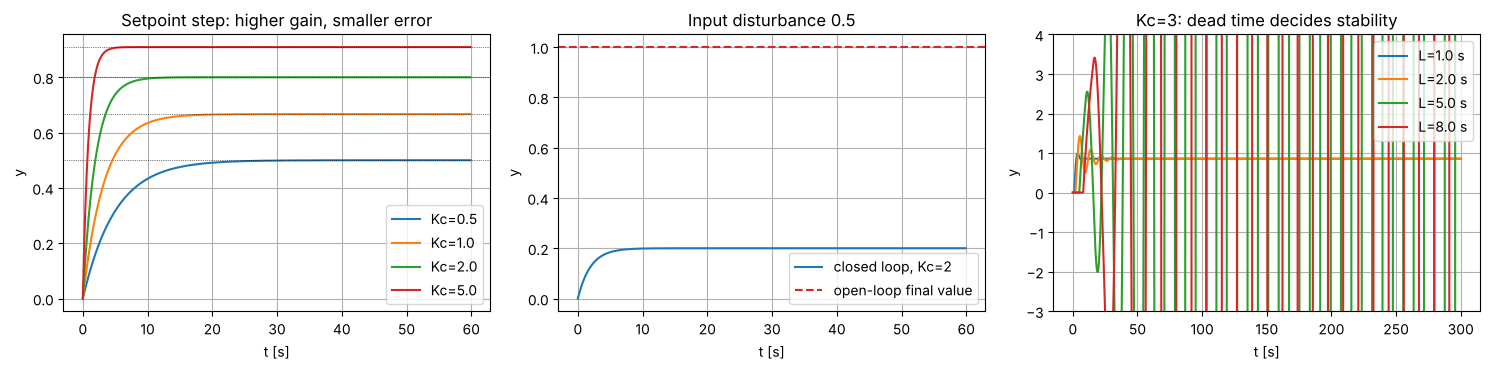

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for Kc in (0.5, 1.0, 2.0, 5.0):
    o = p_loop(Kc, t_end=60.0)
    ax[0].plot(o["t"], o["y"], label=f"Kc={Kc}")
    ax[0].axhline(Kc * K / (1 + Kc * K), color="k", lw=0.5, ls=":")
ax[0].set(title="Setpoint step: higher gain, smaller error", xlabel="t [s]", ylabel="y")
ax[0].legend()
cl = p_loop(2.0, r=0.0, d=0.5, t_end=60.0)
ax[1].plot(cl["t"], cl["y"], label="closed loop, Kc=2")
ax[1].axhline(K * 0.5, color="C3", ls="--", label="open-loop final value")
ax[1].set(title="Input disturbance 0.5", xlabel="t [s]", ylabel="y")
ax[1].legend()
for L, o in runs.items():
    ax[2].plot(o["t"], o["y"], label=f"L={L} s")
ax[2].set(title="Kc=3: dead time decides stability", xlabel="t [s]", ylabel="y", ylim=(-3, 4))
ax[2].legend()
fig.tight_layout()
figs = [save_figure(fig, EXP, "feedback_fundamentals")]
plt.show()

Left: the final value approaches 1 as `Kc K` grows but never reaches it, matching
`Kc K/(1+Kc K)`. Middle: feedback cuts the disturbance effect from 1.0 to 0.2 (the closed form
is `K d/(1+Kc K)`), but a P controller cannot remove it. Right: the same gain is harmless at
`L = 1 s` and destabilising at `L = 5 s`, which is why a loop with long dead time needs a lower
gain (or a different structure).

## 14. Research Discussion and Limitations

**Advantages of feedback shown here:** the disturbance and gain-uncertainty effects shrink by
the factor `1/(1+Kc K)`. **Limits:** (1) a P controller leaves a permanent offset, (2) the
usable gain is bounded by `Ku`, which falls as dead time grows, (3) the study is linear and
noise-free, so actuator saturation, quantisation and sensor noise are not represented.
The delay is a whole number of samples, so the delay actually simulated is `round(L/Ts) Ts`.

## 15. Summary, Exercises, and Further Research

**Key insights.** Loop gain sets the error and the disturbance attenuation; dead time sets the
upper bound on that gain.

**Exercises.** (1) Add integral action and show the offset disappears (see notebook 03).
(2) Find, by bisection on simulation, the `Kc` at which `L = 2 s` becomes unstable and compare
with `Ku`. (3) Add measurement noise and plot the control-signal variance against `Kc`.

**Related.** PID control, PID tuning, transfer-function modelling. **Research directions.**
Delay-compensating structures (Smith predictor) and robustness margins.

In [5]:
rec = ExperimentRecord(
    experiment_id=EXP, title="Feedback fundamentals on a first-order plant",
    notebook="notebooks/01_fundamentals/01_control_fundamentals.ipynb",
    algorithm="Proportional feedback", application="Generic process loop (illustrative)",
    plant_model="FOPDT K=2, T=10 s, L varied",
    dataset={"name": "none", "kind": "simulated",
             "description": "Simulated plant with illustrative parameters."},
    metrics=metrics, checks=checks, sampling_time_s=Ts, random_seed=None,
    controller_parameters={"Kc": [0.5, 1.0, 2.0, 5.0, 3.0]},
    plant_parameters={"K": K, "T_s": T, "L_s": [0, 1, 2, 5, 8]},
    input_configuration={"setpoint_step": 1.0},
    disturbance_configuration={"input_step": 0.5},
    operating_conditions={"noise": "none", "saturation": "none"},
    number_of_trials=1, figure_references=figs,
    limitations=["Linear, noise-free, unsaturated simulation.",
                 "Delay rounded to whole samples.",
                 "No hardware or controller-in-the-loop validation."])
print(rec.save())

experiments/results/exp_01_feedback_fundamentals.json
